In [ ]:
!pip install -q rasterio

import os
import requests
import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 100)

# Bathymetry

In [ ]:
from google.colab import userdata

API_KEY = userdata.get('OPENTOPO_API_KEY')

if API_KEY is None:
    raise ValueError("API key belum diset. Buka ikon kunci di sidebar kiri Colab, "
                      "tambahkan secret bernama 'OPENTOPO_API_KEY', lalu izinkan akses notebook ini.")
print("API key berhasil dimuat.")

API key berhasil dimuat.


In [ ]:
LAT_MIN, LAT_MAX = -4.16, 7.74
LON_MIN, LON_MAX = 102.9, 111.05
GRID_SIZE = 0.1

grid_lat_vals = np.arange(int(np.floor(LAT_MIN / GRID_SIZE)), int(np.floor(LAT_MAX / GRID_SIZE)) + 1)
grid_lon_vals = np.arange(int(np.floor(LON_MIN / GRID_SIZE)), int(np.floor(LON_MAX / GRID_SIZE)) + 1)

grid_df = pd.DataFrame(
    [(la, lo) for la in grid_lat_vals for lo in grid_lon_vals],
    columns=['grid_lat', 'grid_lon']
)
grid_df['center_lat'] = grid_df['grid_lat'] * GRID_SIZE + GRID_SIZE / 2
grid_df['center_lon'] = grid_df['grid_lon'] * GRID_SIZE + GRID_SIZE / 2

print(f"Total grid cell terbentuk: {len(grid_df)}")

Total grid cell terbentuk: 9840


In [ ]:
url = "https://portal.opentopography.org/API/globaldem"
params = {
    "demtype": "GEBCOSubIceTopo",
    "south": LAT_MIN,
    "north": LAT_MAX,
    "west": LON_MIN,
    "east": LON_MAX,
    "outputFormat": "GTiff",
    "API_Key": API_KEY,
}

resp = requests.get(url, params=params)

if resp.status_code != 200:
    raise RuntimeError(f"Download gagal, status code {resp.status_code}: {resp.text[:300]}")

gebco_path = "gebco_wpp711.tif"
with open(gebco_path, "wb") as f:
    f.write(resp.content)

print(f"Berhasil download. Ukuran file: {len(resp.content)/1e6:.2f} MB")

Berhasil download. Ukuran file: 3.68 MB


In [ ]:
with rasterio.open(gebco_path) as src:
    print(f"Raster bounds : {src.bounds}")
    print(f"Raster nodata : {src.nodata}")

    coords = list(zip(grid_df['center_lon'], grid_df['center_lat']))
    sampled_values = [v[0] for v in src.sample(coords)]

grid_df['bathymetry'] = sampled_values

nodata_val = -32767
grid_df.loc[grid_df['bathymetry'] == nodata_val, 'bathymetry'] = np.nan

n_missing = grid_df['bathymetry'].isna().sum()
n_positive = (grid_df['bathymetry'] > 0).sum()

print(f"\nJumlah cell nodata (setelah masking) : {n_missing} dari {len(grid_df)}")
print(f"Jumlah cell nilai positif (daratan)   : {n_positive}")
print("\nStatistik bathymetry (setelah dibersihkan):")
print(grid_df['bathymetry'].describe())

Raster bounds : BoundingBox(left=102.89999999999998, bottom=-4.158333333333326, right=111.04999999999998, top=7.741666666666674)
Raster nodata : -32767.0

Jumlah cell nodata (setelah masking) : 201 dari 9840
Jumlah cell nilai positif (daratan)   : 2076

Statistik bathymetry (setelah dibersihkan):
count    9639.000000
mean      -63.597261
std       241.487465
min     -1979.000000
25%       -66.000000
50%       -39.000000
75%        -7.000000
max      1544.000000
Name: bathymetry, dtype: float64


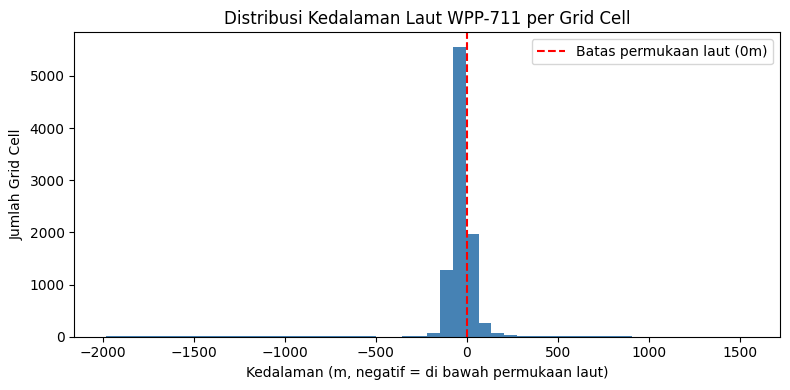

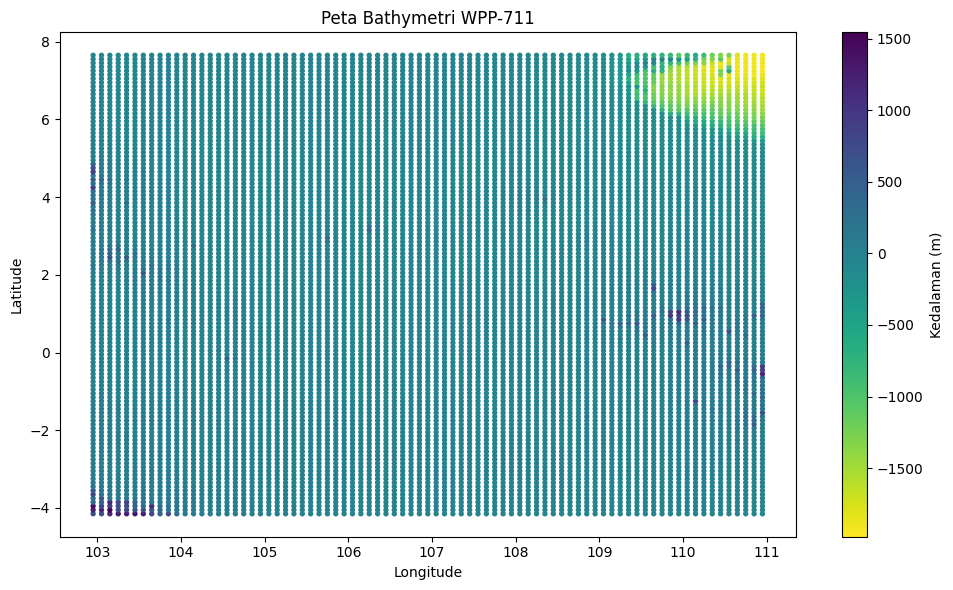

In [ ]:
plt.figure(figsize=(8, 4))
plt.hist(grid_df['bathymetry'].dropna(), bins=50, color='steelblue')
plt.axvline(0, color='red', linestyle='--', label='Batas permukaan laut (0m)')
plt.title('Distribusi Kedalaman Laut WPP-711 per Grid Cell')
plt.xlabel('Kedalaman (m, negatif = di bawah permukaan laut)')
plt.ylabel('Jumlah Grid Cell')
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 6))
sc = plt.scatter(grid_df['center_lon'], grid_df['center_lat'],
                  c=grid_df['bathymetry'], cmap='viridis_r', s=8)
plt.colorbar(sc, label='Kedalaman (m)')
plt.title('Peta Bathymetri WPP-711')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.tight_layout()
plt.show()

In [ ]:
from scipy.spatial import cKDTree

valid = grid_df.dropna(subset=['bathymetry'])
missing = grid_df[grid_df['bathymetry'].isna()]

if len(missing) > 0:
    tree = cKDTree(valid[['center_lon', 'center_lat']].values)
    _, idx = tree.query(missing[['center_lon', 'center_lat']].values)
    grid_df.loc[missing.index, 'bathymetry'] = valid.iloc[idx]['bathymetry'].values

print(f"Sisa nodata setelah fill: {grid_df['bathymetry'].isna().sum()}")

Sisa nodata setelah fill: 0


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os

drive_folder = '/content/drive/MyDrive/oseanografi'
os.makedirs(drive_folder, exist_ok=True)

output_path = os.path.join(drive_folder, 'wpp711_grid_bathymetry.csv')
grid_df.to_csv(output_path, index=False)

print(f"Tersimpan di Drive: {output_path}")

Mounted at /content/drive
Tersimpan di Drive: /content/drive/MyDrive/oseanografi/wpp711_grid_bathymetry.csv


# SST & arus (via Copernicus Marine Service)

In [ ]:
!pip install -q copernicusmarine
import copernicusmarine

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 130.5/130.5 kB 5.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.0/140.0 kB 9.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 78.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.7/363.7 kB 24.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.7/15.7 MB 51.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.2/9.2 MB 57.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.3/117.3 kB 8.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.2/90.2 kB 6.7 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
numba 0.60.0 requires numpy<2.1,>=1.22, but you have numpy 2.5.2 which is incompatible.


In [ ]:
copernicusmarine.login()

INFO - 2026-08-21T02:54:08Z - Downloading Copernicus Marine data requires a Copernicus Marine username and password, sign up for free at: https://data.marine.copernicus.eu/register
INFO:copernicusmarine:Downloading Copernicus Marine data requires a Copernicus Marine username and password, sign up for free at: https://data.marine.copernicus.eu/register


Copernicus Marine username: firfanutsaqib
Copernicus Marine password: ··········


INFO - 2026-08-21T02:54:40Z - Credentials file stored in /root/.copernicusmarine/.copernicusmarine-credentials.
INFO:copernicusmarine:Credentials file stored in /root/.copernicusmarine/.copernicusmarine-credentials.


True

In [ ]:
copernicusmarine.subset(
    dataset_id="cmems_mod_glo_phy-thetao_anfc_0.083deg_P1D-m",
    variables=["thetao"],
    minimum_longitude=LON_MIN,
    maximum_longitude=LON_MAX,
    minimum_latitude=LAT_MIN,
    maximum_latitude=LAT_MAX,
    start_datetime="2023-01-01",
    end_datetime="2025-12-31",
    minimum_depth=0,
    maximum_depth=1,
    output_filename="wpp711_sst_2023_2025.nc",
    output_directory="/content/copernicus_data",
)

INFO - 2026-08-21T02:56:38Z - Selected dataset version: "202406"
INFO:copernicusmarine:Selected dataset version: "202406"
INFO - 2026-08-21T02:56:38Z - Selected dataset part: "default"
INFO:copernicusmarine:Selected dataset part: "default"
WARNING - 2026-08-21T02:56:38Z - Some of your subset selection [0.0, 1.0] for the depth dimension exceed the dataset coordinates [0.49402499198913574, 5727.9169921875]


  0%|          | [00:00<?]

INFO - 2026-08-21T02:56:50Z - Total size of the download: 58.23 MB.
INFO:copernicusmarine:Total size of the download: 58.23 MB.


ResponseSubset(file_path=PosixPath('/content/copernicus_data/wpp711_sst_2023_2025.nc'), output_directory=PosixPath('/content/copernicus_data'), filename='wpp711_sst_2023_2025.nc', file_size=58.2264961832061, data_transfer_size=188.5410687022901, variables=['thetao'], coordinates_extent=[GeographicalExtent(minimum=102.91668701171875, maximum=111.0, unit='degrees_east', coordinate_id='longitude'), GeographicalExtent(minimum=-4.0833282470703125, maximum=7.6666717529296875, unit='degrees_north', coordinate_id='latitude'), TimeExtent(minimum='2023-01-01T00:00:00+00:00', maximum='2025-12-31T00:00:00+00:00', unit='iso8601', coordinate_id='time'), GeographicalExtent(minimum=0.49402499198913574, maximum=0.49402499198913574, unit='m', coordinate_id='depth')], status='000', message='The request was successful.', file_status='DOWNLOADED', file_names=None)

In [ ]:
copernicusmarine.subset(
    dataset_id="cmems_mod_glo_phy-cur_anfc_0.083deg_P1D-m",
    variables=["uo", "vo"],
    minimum_longitude=LON_MIN,
    maximum_longitude=LON_MAX,
    minimum_latitude=LAT_MIN,
    maximum_latitude=LAT_MAX,
    start_datetime="2023-01-01",
    end_datetime="2025-12-31",
    minimum_depth=0,
    maximum_depth=1,
    output_filename="wpp711_current_2023_2025.nc",
    output_directory="/content/copernicus_data",
)

INFO - 2026-08-21T02:57:07Z - Selected dataset version: "202406"
INFO:copernicusmarine:Selected dataset version: "202406"
INFO - 2026-08-21T02:57:07Z - Selected dataset part: "default"
INFO:copernicusmarine:Selected dataset part: "default"
WARNING - 2026-08-21T02:57:07Z - Some of your subset selection [0.0, 1.0] for the depth dimension exceed the dataset coordinates [0.49402499198913574, 5727.9169921875]


  0%|          | [00:00<?]

INFO - 2026-08-21T02:57:26Z - Total size of the download: 116.44 MB.
INFO:copernicusmarine:Total size of the download: 116.44 MB.


ResponseSubset(file_path=PosixPath('/content/copernicus_data/wpp711_current_2023_2025.nc'), output_directory=PosixPath('/content/copernicus_data'), filename='wpp711_current_2023_2025.nc', file_size=116.43999236641221, data_transfer_size=377.0821374045802, variables=['uo', 'vo'], coordinates_extent=[GeographicalExtent(minimum=102.91668701171875, maximum=111.0, unit='degrees_east', coordinate_id='longitude'), GeographicalExtent(minimum=-4.0833282470703125, maximum=7.6666717529296875, unit='degrees_north', coordinate_id='latitude'), TimeExtent(minimum='2023-01-01T00:00:00+00:00', maximum='2025-12-31T00:00:00+00:00', unit='iso8601', coordinate_id='time'), GeographicalExtent(minimum=0.49402499198913574, maximum=0.49402499198913574, unit='m', coordinate_id='depth')], status='000', message='The request was successful.', file_status='DOWNLOADED', file_names=None)

In [ ]:
import xarray as xr

ds_sst = xr.open_dataset("/content/copernicus_data/wpp711_sst_2023_2025.nc")
ds_cur = xr.open_dataset("/content/copernicus_data/wpp711_current_2023_2025.nc")

sst = ds_sst['thetao'].squeeze('depth', drop=True)
uo = ds_cur['uo'].squeeze('depth', drop=True)
vo = ds_cur['vo'].squeeze('depth', drop=True)
speed = np.sqrt(uo**2 + vo**2)

sst_mean_2d = sst.mean(dim='time')
sst_std_2d = sst.std(dim='time')
speed_mean_2d = speed.mean(dim='time')
speed_std_2d = speed.std(dim='time')

print("Dimensi sst_mean_2d:", sst_mean_2d.dims, sst_mean_2d.shape)

Dimensi sst_mean_2d: ('latitude', 'longitude') (142, 98)


In [ ]:
def sample_2d(da, lons, lats):
    return da.sel(
        longitude=xr.DataArray(lons, dims='points'),
        latitude=xr.DataArray(lats, dims='points'),
        method='nearest'
    ).values

lons = grid_df['center_lon'].values
lats = grid_df['center_lat'].values

grid_df['sst_mean'] = sample_2d(sst_mean_2d, lons, lats)
grid_df['sst_std'] = sample_2d(sst_std_2d, lons, lats)
grid_df['current_speed_mean'] = sample_2d(speed_mean_2d, lons, lats)
grid_df['current_speed_std'] = sample_2d(speed_std_2d, lons, lats)

print(grid_df[['sst_mean', 'sst_std', 'current_speed_mean', 'current_speed_std']].describe())

          sst_mean      sst_std  current_speed_mean  current_speed_std
count  7764.000000  7764.000000         7764.000000        7764.000000
mean     29.466829     1.151973            0.238020           0.123773
std       0.402025     0.288529            0.085946           0.057473
min      28.531792     0.596076            0.011029           0.005668
25%      29.149300     0.900113            0.188670           0.089429
50%      29.498411     1.111773            0.233305           0.112635
75%      29.727983     1.396595            0.287075           0.153011
max      31.122437     1.730387            0.527076           0.330174


In [ ]:
from scipy.spatial import cKDTree

def fill_nearest(df, cols, lon_col='center_lon', lat_col='center_lat'):
    """Isi NaN di kolom-kolom tertentu pakai nilai grid tetangga terdekat."""
    for col in cols:
        valid = df.dropna(subset=[col])
        missing = df[df[col].isna()]
        if len(missing) > 0:
            tree = cKDTree(valid[[lon_col, lat_col]].values)
            _, idx = tree.query(missing[[lon_col, lat_col]].values)
            df.loc[missing.index, col] = valid.iloc[idx][col].values
    return df

cols_to_fill = ['sst_mean', 'sst_std', 'current_speed_mean', 'current_speed_std']
grid_df = fill_nearest(grid_df, cols_to_fill)

print("Sisa NaN per kolom:")
print(grid_df[cols_to_fill].isna().sum())

Sisa NaN per kolom:
sst_mean              0
sst_std               0
current_speed_mean    0
current_speed_std     0
dtype: int64


# Klorofil Laut

In [ ]:
import ee
ee.Authenticate()
ee.Initialize(project='darvin-natuna-2025')
print("GEE berhasil diinisialisasi.")

GEE berhasil diinisialisasi.


In [ ]:
chl_img = ee.ImageCollection('NASA/OCEANDATA/MODIS-Aqua/L3SMI') \
    .filterDate('2023-01-01', '2025-12-31') \
    .select('chlor_a') \
    .mean()

print("Image klorofil rata-rata 2023-2025 siap.")

Image klorofil rata-rata 2023-2025 siap.


In [ ]:
def sample_chlorophyll_batch(df_chunk):
    points = ee.FeatureCollection([
        ee.Feature(ee.Geometry.Point([lon, lat]), {'grid_lat': int(glat), 'grid_lon': int(glon)})
        for glat, glon, lat, lon in zip(df_chunk['grid_lat'], df_chunk['grid_lon'],
                                          df_chunk['center_lat'], df_chunk['center_lon'])
    ])
    result = chl_img.reduceRegions(collection=points, reducer=ee.Reducer.first(), scale=4000).getInfo()
    return pd.DataFrame([{
        'grid_lat': f['properties']['grid_lat'],
        'grid_lon': f['properties']['grid_lon'],
        'chlorophyll_mean': f['properties'].get('first')
    } for f in result['features']])

In [ ]:
chunk_size = 2000
chl_results = []

for i in range(0, len(grid_df), chunk_size):
    chunk = grid_df.iloc[i:i+chunk_size]
    chl_results.append(sample_chlorophyll_batch(chunk))
    print(f"Selesai batch {i} - {i+len(chunk)} dari {len(grid_df)}")

chl_df = pd.concat(chl_results, ignore_index=True)
grid_df = grid_df.merge(chl_df, on=['grid_lat', 'grid_lon'], how='left')

print("\nStatistik chlorophyll_mean:")
print(grid_df['chlorophyll_mean'].describe())

Selesai batch 0 - 2000 dari 9840
Selesai batch 2000 - 4000 dari 9840
Selesai batch 4000 - 6000 dari 9840
Selesai batch 6000 - 8000 dari 9840
Selesai batch 8000 - 9840 dari 9840

Statistik chlorophyll_mean:
count    7851.000000
mean        0.960593
std         2.006211
min         0.099444
25%         0.129190
50%         0.233090
75%         0.532930
max        23.646372
Name: chlorophyll_mean, dtype: float64


In [ ]:
grid_df = fill_nearest(grid_df, ['chlorophyll_mean'])
print("Sisa NaN chlorophyll_mean:", grid_df['chlorophyll_mean'].isna().sum())

Sisa NaN chlorophyll_mean: 0


In [ ]:
bathy_df = pd.read_csv('/content/drive/MyDrive/oseanografi/wpp711_grid_bathymetry.csv')

ocean_features = grid_df[['grid_lat', 'grid_lon', 'sst_mean', 'sst_std',
                           'current_speed_mean', 'current_speed_std', 'chlorophyll_mean']]

grid_full = bathy_df.merge(ocean_features, on=['grid_lat', 'grid_lon'], how='left')

output_path = '/content/drive/MyDrive/oseanografi/wpp711_grid_environmental_full.csv'
grid_full.to_csv(output_path, index=False)

print(f"Tersimpan: {output_path}")
print(f"Total baris: {len(grid_full)}")
print(f"Total kolom missing:\n{grid_full.isna().sum()}")
display(grid_full.head())

Tersimpan: /content/drive/MyDrive/oseanografi/wpp711_grid_environmental_full.csv
Total baris: 9840
Total kolom missing:
grid_lat              0
grid_lon              0
center_lat            0
center_lon            0
bathymetry            0
sst_mean              0
sst_std               0
current_speed_mean    0
current_speed_std     0
chlorophyll_mean      0
dtype: int64


,grid_lat,grid_lon,center_lat,center_lon,bathymetry,sst_mean,sst_std,current_speed_mean,current_speed_std,chlorophyll_mean
0,-42,1029,-4.15,102.95,686.0,30.480637,0.778808,0.025672,0.018001,6.584374
1,-42,1030,-4.15,103.05,584.0,30.480637,0.778808,0.025672,0.018001,6.584374
2,-42,1031,-4.15,103.15,1187.0,30.480637,0.778808,0.025672,0.018001,6.584374
3,-42,1032,-4.15,103.25,1274.0,30.480637,0.778808,0.025672,0.018001,6.584374
4,-42,1033,-4.15,103.35,1289.0,30.480637,0.778808,0.025672,0.018001,6.584374
